<a href="https://colab.research.google.com/github/kalyanisingh19196-netizen/Neural-Networks-and-Deep-Learning-Lab/blob/main/Assignment-3-Optimization/regularization_overfitting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 9000
Validation samples: 1000
Testing samples: 2000

Training: Baseline
Epoch 1/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6859 - loss: 0.9067 - val_accuracy: 0.7780 - val_loss: 0.6127
Epoch 2/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8076 - loss: 0.5495 - val_accuracy: 0.8100 - val_loss: 0.5235
Epoch 3/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8347 - loss: 0.4780 - val_accuracy: 0.8250 - val_loss: 0.4885
Epoch 4/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8476 - loss: 0.4377 - val_accuracy: 0.8140 - val_loss: 0.4945
Epoch 5/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8566 - loss: 0.4080 - val_accuracy: 0.8070 - val_loss: 0.5011
Epoch 6/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8644 - loss: 0.3814 - val_ac

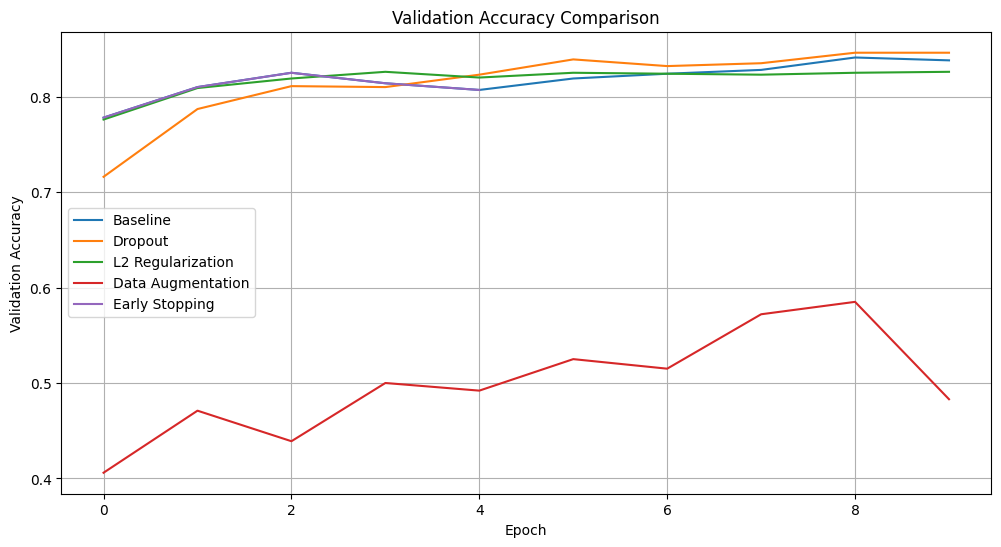

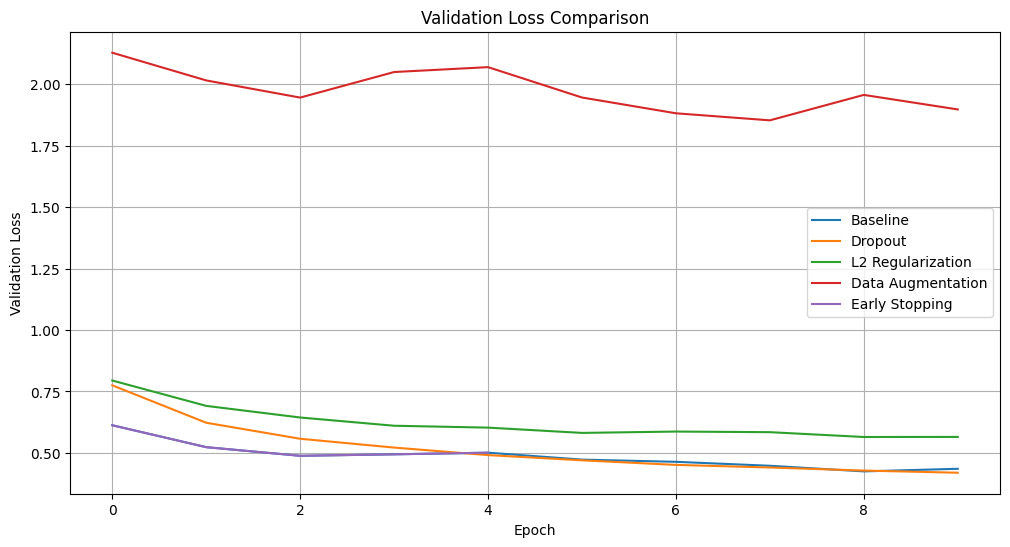

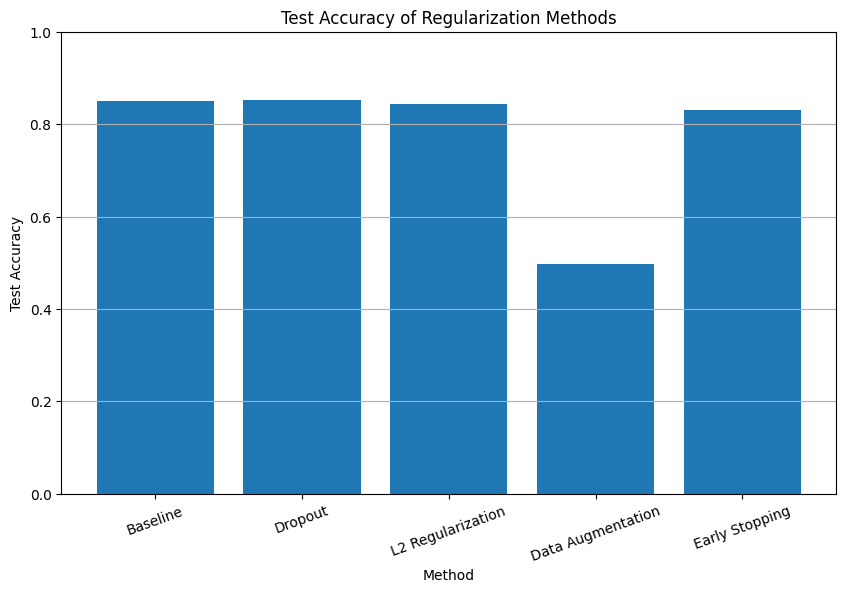

In [1]:
# Assignment 3 - Preventing Overfitting in Neural Networks

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, regularizers

# 1. Load Fashion-MNIST dataset
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Use smaller subsets to reduce training time
X_train = X_train[:10000]
y_train = y_train[:10000]

X_test = X_test[:2000]
y_test = y_test[:2000]

# Split training data into training and validation sets
np.random.seed(42)
indices = np.random.permutation(len(X_train))

train_indices = indices[1000:]
val_indices = indices[:1000]

X_val = X_train[val_indices]
y_val = y_train[val_indices]

X_train = X_train[train_indices]
y_train = y_train[train_indices]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


# 2. Create a neural network
def create_model(method):

    model = tf.keras.Sequential()
    model.add(layers.Input(shape=(28, 28)))

    # Data augmentation
    if method == "Data Augmentation":
        model.add(layers.RandomRotation(0.05))
        model.add(layers.RandomTranslation(0.05, 0.05))

    model.add(layers.Flatten())

    # L2 regularization
    if method == "L2 Regularization":
        model.add(layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ))
    else:
        model.add(layers.Dense(128, activation="relu"))

    # Dropout
    if method == "Dropout":
        model.add(layers.Dropout(0.5))

    model.add(layers.Dense(64, activation="relu"))

    if method == "Dropout":
        model.add(layers.Dropout(0.3))

    model.add(layers.Dense(10, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# 3. Train and compare different methods
methods = [
    "Baseline",
    "Dropout",
    "L2 Regularization",
    "Data Augmentation",
    "Early Stopping"
]

histories = {}
results = []

for method in methods:

    print("\nTraining:", method)

    tf.keras.utils.set_random_seed(42)

    model = create_model(method)

    callbacks = []

    # Early stopping
    if method == "Early Stopping":
        callbacks.append(
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=2,
                restore_best_weights=True
            )
        )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=128,
        callbacks=callbacks,
        verbose=1
    )

    # Evaluate on test data
    test_loss, test_accuracy = model.evaluate(
        X_test, y_test, verbose=0
    )

    histories[method] = history.history

    results.append({
        "Method": method,
        "Epochs Trained": len(history.history["loss"]),
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss
    })


# 4. Display comparison table
results_df = pd.DataFrame(results)

print("\nREGULARIZATION COMPARISON")
print(results_df.to_string(index=False))


# 5. Plot training and validation accuracy
plt.figure(figsize=(12, 6))

for method, history in histories.items():
    plt.plot(history["val_accuracy"], label=method)

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# 6. Plot training and validation loss
plt.figure(figsize=(12, 6))

for method, history in histories.items():
    plt.plot(history["val_loss"], label=method)

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# 7. Compare final test accuracy
plt.figure(figsize=(10, 6))

plt.bar(
    results_df["Method"],
    results_df["Test Accuracy"]
)

plt.title("Test Accuracy of Regularization Methods")
plt.xlabel("Method")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.show()